# Problem Statement - Resilient Regional Fuel Depot Network Design

This notebook formulates and solves a series of mixed-integer linear programming (MILP) models for locating fuel depots across a regional road network. Vehicles can travel at most $D_{\max}$ kilometers between refueling stops. The design goal is to minimize the number of opened depots under three progressively stricter operational requirements:

1. **Baseline Model (`BASE`):** Every location lies within $D_{\max}$ of at least one depot, and all opened depots form a single connected backbone.
2. **Scenario A (`DEPOT_FAIL`):** The network remains covered and connected after the outage of any single opened fuel depot.
3. **Scenario B (`NODE_FAIL`):** The network remains covered and connected after the disruption of any single node in the road network (whether it hosts a depot or not).

Each model is implemented in Python using `gurobipy` and evaluated on the small (10-node), medium (20-node), and large (30-node) road network instances.




## Setup and Imports



In [ ]:
# ===========================
# 1) Setup and Imports
# ===========================

import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx
import gurobipy as gp
from gurobipy import GRB
from itertools import combinations
import numpy as np
from IPython.display import HTML
import base64
import io

Imports loaded.


In [7]:
data_1 = {
  "metadata": {
    "description": "Graph with bridge nodes. Solutions: RLP=2, RLPRF=5, RLPNF=6. RLPNF protects against all node failures.",
    "n_locations": 10,
    "n_roads": 18,
    "area_size_km": 31.32203652780238,
    "instance_id": "student_instance_small"
  },
  "locations": {
    "0": {"x_km": 0.22370578944475894,"y_km": -0.7210122786959163,"id": 0},
    "1": {"x_km": 9.584289297070436,"y_km": -0.2672763134126166,"id": 1},
    "2": {"x_km": 19.912139968434072,"y_km": 0.5703519227860272,"id": 2},
    "3": {"x_km": 29.39934756431672,"y_km": 0.02846887682722321,"id": 3},
    "4": {"x_km": 0.18482913772408494,"y_km": 9.092900825439996,"id": 4},
    "5": {"x_km": 10.215089703802876,"y_km": 9.341048247374584,"id": 5},
    "6": {"x_km": 19.130103185970558,"y_km": 10.897771074506666,"id": 6},
    "7": {"x_km": 30.93126406614912,"y_km": 10.616794696232922,"id": 7},
    "8": {"x_km": -0.39077246165325863,"y_km": 19.195344228012768,"id": 8},
    "9": {"x_km": 10.368466053024314,"y_km": 19.880304987479203,"id": 9}
  },
    
 "road_network": {
    "edges": [
      [0,1],[0,4],[0,5],
      [1,2],[1,4],[1,5],
      [2,3],[2,5],[2,6],
      [3,7],
      [4,5],[4,8],
      [5,6],[5,8],[5,9],
      [6,7],[6,9],
      [8,9]
],
    "travel_distance_km": {
      "0,1": 9.37,"0,4": 9.81,"0,5": 14.18,
      "1,2": 10.36,"1,4": 13.27,"1,5": 9.63,
      "2,3": 9.5,"2,5": 13.08,"2,6": 10.36,
      "3,7": 10.7,
      "4,5": 10.03,"4,8": 10.12,
      "5,6": 9.05,"5,8": 14.48,"5,9": 10.54,
      "6,7": 11.8,"6,9": 12.55,
      "8,9": 10.78
    }
  }
}

data_2 = {
    "metadata": {
        "description": "Graph with bridge nodes. Solutions: RLP=3, RLPRF=6, RLPNF=6. RLPNF protects against all node failures.",
        "n_locations": 30,
        "n_roads": 57,
        "area_size_km": 77.08613631876793,
        "instance_id": "student_instance_large"
    },

    "locations": {
        "0":  {"x_km": 0.507941348886817,  "y_km": 0.25780965768663866, "id": 0},
        "1":  {"x_km": 15.3747105062868,   "y_km": 0.5240671529634744,  "id": 1},
        "2":  {"x_km": 31.02702731286077,  "y_km": -1.2504150350026837, "id": 2},
        "3":  {"x_km": 45.791048524330016, "y_km": -0.769000876389378,  "id": 3},
        "4":  {"x_km": 59.08266888173631,  "y_km": 0.21737087247441922, "id": 4},
        "5":  {"x_km": 73.78713754983715,  "y_km": 1.1559804788254189,  "id": 5},
        "6":  {"x_km": 0.3817469161538063, "y_km": 15.670249074569863,  "id": 6},
        "7":  {"x_km": 13.54838762008505,  "y_km": 15.283295638335128,  "id": 7},
        "8":  {"x_km": 30.170355577182868, "y_km": 13.976878932434168,  "id": 8},
        "9":  {"x_km": 43.959211545374316, "y_km": 15.586588586312732,  "id": 9},
        "10": {"x_km": 59.45629927914563,  "y_km": 15.575910886595459,  "id": 10},
        "11": {"x_km": 75.16314974915332,  "y_km": 14.666851722369433,  "id": 11},
        "12": {"x_km": 1.275397468841958,  "y_km": 31.02500999073815,   "id": 12},
        "13": {"x_km": 14.572192700049529, "y_km": 28.63077439139712,   "id": 13},
        "14": {"x_km": 29.41430422023329,  "y_km": 29.694557045753943,  "id": 14},
        "15": {"x_km": 45.61487649135409,  "y_km": 31.486075446102053,  "id": 15},
        "16": {"x_km": 59.56774459715238,  "y_km": 30.787643441356302,  "id": 16},
        "17": {"x_km": 75.27953074968666,  "y_km": 30.575105396100533,  "id": 17},
        "18": {"x_km": -1.0466176429557592,"y_km": 44.69662887817847,   "id": 18},
        "19": {"x_km": 14.222567693170873, "y_km": 44.53036804214497,   "id": 19},
        "20": {"x_km": 30.039384462597006, "y_km": 45.49987365049221,   "id": 20},
        "21": {"x_km": 43.81772545517044,  "y_km": 43.89268485199224,   "id": 21},
        "22": {"x_km": 59.465941819404925, "y_km": 45.48469300999873,   "id": 22},
        "23": {"x_km": 76.03951867581216,  "y_km": 45.15977203439014,   "id": 23},
        "24": {"x_km": 1.0633574625735145, "y_km": 59.65451343382728,   "id": 24},
        "25": {"x_km": 14.45036369135514,  "y_km": 59.56279402677504,   "id": 25},
        "26": {"x_km": 29.013245487615297, "y_km": 60.98733790350567,   "id": 26},
        "27": {"x_km": 44.51601253774298,  "y_km": 60.15711022588222,   "id": 27},
        "28": {"x_km": 60.235654404326496, "y_km": 60.064599178192,     "id": 28},
        "29": {"x_km": 73.50806419372296,  "y_km": 61.46503625784846,   "id": 29}
    },

    "road_network": {
        "edges": [
            [0,1], [0,6], [0,7],
            [1,2], [1,7], [1,8],
            [2,3], [2,8],
            [3,4], [3,9],
            [4,5], [4,10],
            [5,11],
            [6,7], [6,12], [6,13],
            [7,8], [7,12], [7,13],
            [8,9], [8,14],
            [9,10], [9,15],
            [10,11], [10,16],
            [11,17],
            [12,13], [12,18], [12,19],
            [13,14], [13,19],
            [14,15], [14,20], [14,21],
            [15,16], [15,21], [15,22],
            [16,17], [16,22],
            [17,23],
            [18,19], [18,24],
            [19,20], [19,24], [19,25],
            [20,21], [20,26],
            [21,22], [21,27],
            [22,23], [22,28],
            [23,29],
            [24,25],
            [25,26],
            [26,27],
            [27,28],
            [28,29]
        ],

        "travel_distance_km": {
            "0,1":14.87, "0,6":15.41, "0,7":19.9,
            "1,2":15.75, "1,7":14.87, "1,8":20.0,
            "2,3":14.77, "2,8":15.25,
            "3,4":13.33, "3,9":16.46,
            "4,5":14.73, "4,10":15.36,
            "5,11":13.58,
            "6,7":13.17, "6,12":15.38, "6,13":19.22,
            "7,8":16.67, "7,12":19.96, "7,13":13.39,
            "8,9":13.88, "8,14":15.74,
            "9,10":15.5,  "9,15":15.99,
            "10,11":15.73,"10,16":15.21,
            "11,17":15.91,
            "12,13":13.51,"12,18":13.87,"12,19":18.71,
            "13,14":14.88,"13,19":15.9,
            "14,15":16.3, "14,20":15.82,"14,21":20.22,
            "15,16":13.97,"15,21":12.54,"15,22":19.69,
            "16,17":15.71,"16,22":14.7,
            "17,23":14.6,
            "18,19":15.27,"18,24":15.11,
            "19,20":15.85,"19,24":20.05,"19,25":15.03,
            "20,21":13.87,"20,26":15.52,
            "21,22":15.73,"21,27":16.28,
            "22,23":16.58,"22,28":14.6,
            "23,29":16.5,
            "24,25":13.39,
            "25,26":14.63,
            "26,27":15.52,
            "27,28":15.72,
            "28,29":13.35
        }
    }
}

data_20 = {
  "metadata": {
    "description": "Graph structured like the updated image with selective bridges and varied distances.",
    "n_locations": 20,
    "n_roads": 40,
    "area_size_km": 60.0,
    "instance_id": "student_instance_20nodes_v4"
  },
  "locations": {
    "0": {"x_km": 0.5, "y_km": 0.3, "id": 0},
    "1": {"x_km": 8.0, "y_km": 0.5, "id": 1},
    "2": {"x_km": 16.0, "y_km": -0.2, "id": 2},
    "3": {"x_km": 24.0, "y_km": 0.8, "id": 3},
    "4": {"x_km": 32.0, "y_km": 0.0, "id": 4},
    "5": {"x_km": 40.0, "y_km": 0.7, "id": 5},
    "6": {"x_km": 0.0, "y_km": 10.0, "id": 6},
    "7": {"x_km": 8.0, "y_km": 10.5, "id": 7},
    "8": {"x_km": 16.0, "y_km": 9.8, "id": 8},
    "9": {"x_km": 24.0, "y_km": 11.0, "id": 9},
    "10": {"x_km": 32.0, "y_km": 10.2, "id": 10},
    "11": {"x_km": 40.0, "y_km": 10.7, "id": 11},
    "12": {"x_km": 0.0, "y_km": 20.0, "id": 12},
    "13": {"x_km": 8.0, "y_km": 19.5, "id": 13},
    "14": {"x_km": 16.0, "y_km": 20.2, "id": 14},
    "15": {"x_km": 24.0, "y_km": 21.0, "id": 15},
    "16": {"x_km": 32.0, "y_km": 20.1, "id": 16},
    "17": {"x_km": 40.0, "y_km": 20.5, "id": 17},
    "18": {"x_km": 0.0, "y_km": 30.0, "id": 18},
    "19": {"x_km": 24.0, "y_km": 30.0, "id": 19}
  },
  "road_network": {
    "edges": [
      [0,1],[0,6],[1,2],[1,7],[2,3],[2,8],[3,4],[3,9],[4,5],[4,10],[5,11],
      [6,7],[6,12],[7,8],[8,9],[8,14],[9,10],[9,15],[10,11],[10,16],[11,17],
      [12,13],[12,18],[13,14],[14,15],[15,16],[15,19],[16,17],[16,19],[17,19],[18,19],
      [8,15],[4,9], [7,12], [7,13], [10,17]

    ],
    "travel_distance_km": {
      "0,1":7.6,"0,6":10.1,"1,2":8.2,"1,7":10.4,"2,3":8.0,"2,8":10.3,
      "3,4":7.9,"3,9":10.1,"4,5":8.1,"4,10":10.2,"5,11":8.0,
      "6,7":8.1,"6,12":10.0,"7,8":8.3,"8,9":8.2,"8,14":10.5,
      "9,10":7.9,"9,15":10.1,"10,11":8.0,"10,16":10.3,"11,17":8.2,
      "12,13":8.1,"12,18":10.2,"13,14":8.0,"14,15":8.3,
      "15,16":8.1,"15,19":10.0,"16,17":8.2,"16,19":10.1,
      "17,19":10.2,"18,19":10.0,
      "8,15":14.5, "4,9": 14.3, "7,12":14.1, "7,13":10.6, "10,17":14.4
    }
  }
}

# Section 1: Baseline Connectivity Model (`Baseline`)

## 1.1 Mathematical Formulation

### Reachability Graph
Let $G = (V, E, w)$ represent the road network with shortest-path distances $d_{ij}$ between nodes $i, j \in V$, and let $n = |V|$. We construct the undirected reachability graph $H = (V, L)$ where:
$$\{i, j\} \in L \iff i \neq j \text{ and } d_{ij} \le D_{\max}.$$
An edge in $L$ indicates that a vehicle can drive directly between $i$ and $j$ on a single tank. For each node $i \in V$, define:
- $N(i) = \{j \in V : \{i, j\} \in L\}$: open neighborhood of nodes reachable from $i$ in one leg,
- $N[i] = N(i) \cup \{i\}$: closed neighborhood of $i$ (including $i$ itself),
- $\vec{L} = \{(i, j), (j, i) : \{i, j\} \in L\}$: set of directed links corresponding to $L$.

### Decision Variables
$$\begin{aligned}
x_i &\in \{0, 1\} && \forall i \in V && \text{(1 if a fuel depot is opened at node } i\text{)}, \\
a_i &\in \{0, 1\} && \forall i \in V && \text{(1 if node } i \text{ is chosen as the anchor depot for connectivity flow)}, \\
z_i &\ge 0 && \forall i \in V && \text{(total connectivity flow injected at node } i\text{)}, \\
y_{ij} &\ge 0 && \forall (i, j) \in \vec{L} && \text{(auxiliary flow on directed link } (i, j) \text{ enforcing backbone connectivity)}.
\end{aligned}$$

### Objective Function
$$\min \sum_{i \in V} x_i \tag{B-0}$$

### Constraints
1. **Anchor Depot Selection:** Exactly one node is designated as the anchor, and it must be an opened depot:
$$\sum_{i \in V} a_i = 1 \tag{B-1}$$
$$a_i \le x_i \quad \forall i \in V \tag{B-2}$$

2. **Closed-Neighborhood Coverage:** Every node must either host a fuel depot or lie within $D_{\max}$ of at least one opened depot:
$$\sum_{j \in N[i]} x_j \ge 1 \quad \forall i \in V \tag{B-3}$$

3. **Backbone Connectivity via Flow-Balance Equalities:** Every opened depot consumes $1$ unit of flow, and only the anchor depot can inject flow into the network:
$$\sum_{j \in N(i)} y_{ij} - \sum_{j \in N(i)} y_{ji} = z_i - x_i \quad \forall i \in V \tag{B-4}$$
$$z_i \le n \cdot a_i \quad \forall i \in V \tag{B-5}$$
$$\sum_{i \in N(j)} y_{ij} \le (n - 1) x_j \quad \forall j \in V \tag{B-6}$$

Summing (B-4) over all $i \in V$ gives $\sum_{i \in V} z_i = \sum_{i \in V} x_i$. Because (B-1) and (B-5) restrict $z_i$ to be positive only at the single anchor node, the anchor injects exactly $\sum_{h \in V} x_h$ units (keeping $1$ for itself and sending $\sum_{h \in V} x_h - 1$ outward), each other opened depot absorbs $1$ unit, and (B-6) prevents flow from entering non-depot nodes. Every opened depot must therefore be reachable from the anchor using only other opened depots as intermediate stops.


## 1.2 Implementation

Implement the  model in the cell below.

In [15]:
# ------------------------------------------------------------
# Load dataset (small / medium / large)
# ------------------------------------------------------------
def select_dataset(option, data_1, data_2, data_20):
    if option == 1:
        return data_1, 20
    elif option == 2:
        return data_2, 44.31
    elif option == 3:
        return data_20, 20
    else:
        raise ValueError("Choose dataset 1, 2, or 3.")

def fig_to_base64():
    buf = io.BytesIO()
    plt.savefig(buf, format="png", bbox_inches="tight")
    buf.seek(0)
    img_b64 = base64.b64encode(buf.read()).decode("utf-8")
    buf.close()
    return img_b64

# ------------------------------------------------------------
# Build graph from raw dataset
# ------------------------------------------------------------
def build_graph(data):
    G = nx.Graph()
    for (a, b) in data["road_network"]["edges"]:
        key1 = f"{a},{b}"
        key2 = f"{b},{a}"
        dist = data["road_network"]["travel_distance_km"].get(
            key1, data["road_network"]["travel_distance_km"].get(key2)
        )
        G.add_edge(a, b, weight=dist)
    return G


# ------------------------------------------------------------
# Compute all-pairs shortest paths
# ------------------------------------------------------------
def compute_shortest_paths(G):
    return dict(nx.all_pairs_dijkstra_path_length(G, weight="weight"))


# ------------------------------------------------------------
# Construct closure graph [G]^c = (V, E^c) and directed arcs A^c
# ------------------------------------------------------------
def construct_closure_sets(G, all_shortest_paths, D_max):
    V = list(G.nodes())

    # Undirected closure edges: {i, j} in E^c iff i != j and d_ij <= D_max
    E_c = [
        (i, j)
        for i in V
        for j in V
        if i < j and all_shortest_paths[i].get(j, float("inf")) <= D_max
    ]

    # Adjacency list in the closure graph (since E^c is undirected, j in neighbors[i] <=> (i,j) and (j,i) in A^c)
    neighbors = {
        i: [
            j
            for j in V
            if j != i and all_shortest_paths[i].get(j, float("inf")) <= D_max
        ]
        for i in V
    }

    # Directed arc set A^c
    A_c = [(i, j) for i in V for j in neighbors[i]]

    return V, E_c, A_c, neighbors


# ------------------------------------------------------------
# Build the Baseline Fuel Depot Connectivity model (B-0 to B-6)
# ------------------------------------------------------------
# ------------------------------------------------------------
# Build the Baseline Fuel Depot Connectivity model (B-0 to B-6)
# ------------------------------------------------------------
def build_model(V, A_c, neighbors):
    n = len(V)

    model = gp.Model("Fuel_Depot_Baseline")

    # Solver parameters
    model.setParam("MIPGap", 0.0)
    model.setParam("Threads", 1)
    model.setParam("Seed", 1)
    model.setParam("MIPFocus", 1)
    model.setParam("Presolve", 2)
    model.setParam("Heuristics", 0.1)

    ############################################################################
    # 1. Decision Variables
    ############################################################################
    # x[i] = 1 if a fuel depot is opened at node i
    x = model.addVars(V, vtype=GRB.BINARY, name="x")

    # a[i] = 1 if node i is chosen as the anchor depot
    a = model.addVars(V, vtype=GRB.BINARY, name="a")

    # z[i] >= 0 total connectivity flow injected at node i
    z = model.addVars(V, lb=0.0, vtype=GRB.CONTINUOUS, name="z")

    # y[i, j] >= 0 auxiliary flow on directed link (i, j)
    y = model.addVars(A_c, lb=0.0, vtype=GRB.CONTINUOUS, name="y")

    ############################################################################
    # 2. Objective (B-0): Minimize total number of opened fuel depots
    ############################################################################
    model.setObjective(gp.quicksum(x[i] for i in V), GRB.MINIMIZE)

    ############################################################################
    # 3. Constraints
    ############################################################################
    # (B-1) Exactly one anchor depot is chosen
    model.addConstr(gp.quicksum(a[i] for i in V) == 1, name="Anchor_Count")

    # (B-2) Anchor must be an opened fuel depot
    model.addConstrs((a[i] <= x[i] for i in V), name="Anchor_Must_Be_Open")

    # (B-3) Closed-neighborhood coverage: node i itself or at least one reachable neighbor is open
    model.addConstrs(
        (x[i] + gp.quicksum(x[j] for j in neighbors[i]) >= 1 for i in V),
        name="Closed_Neighborhood_Coverage",
    )

    # (B-4) Flow-balance equalities at every node
    model.addConstrs(
        (
            gp.quicksum(y[i, j] for j in neighbors[i])
            - gp.quicksum(y[j, i] for j in neighbors[i])
            == z[i] - x[i]
            for i in V
        ),
        name="Flow_Balance",
    )

    # (B-5) Only the anchor depot can inject flow
    model.addConstrs((z[i] <= n * a[i] for i in V), name="Anchor_Flow_Injection")

    # (B-6) Flow can only enter opened fuel depots
    model.addConstrs(
        (
            gp.quicksum(y[i, j] for i in neighbors[j]) <= (n - 1) * x[j]
            for j in V
        ),
        name="Flow_Into_Open_Only",
    )

    return model, x, a, y

def visualize_solution(data, G, all_shortest_paths, open_hubs, D_max, title=None):
    V = list(G.nodes())
    pos = {
        i: (data["locations"][str(i)]["x_km"],
            data["locations"][str(i)]["y_km"])
        for i in V
    }

    plt.figure(figsize=(12, 7))

    # Map each node to its closest reachable hub
    node_to_hub = {}
    for i in V:
        reachable = [
            (h, all_shortest_paths[i][h])
            for h in open_hubs
            if all_shortest_paths[i].get(h, float("inf")) <= D_max
        ]
        node_to_hub[i] = min(reachable, key=lambda x: x[1])[0] if reachable else None

    # Node colors
    node_colors = []
    for i in V:
        if i in open_hubs:
            node_colors.append("red")      # hub
        elif node_to_hub[i] is not None:
            node_colors.append("skyblue")  # covered
        else:
            node_colors.append("gray")     # uncovered (stranded)

    # Draw network
    nx.draw_networkx_edges(G, pos, width=1.5, alpha=0.7)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=480)
    nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")

    edge_labels = {(u, v): f"{d['weight']:.1f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

    # Draw shortest-path assignment lines
    for node, hub in node_to_hub.items():
        if hub is not None and node != hub:
            path = nx.shortest_path(G, node, hub, weight="weight")
            coords = [pos[n] for n in path]
            xs, ys = zip(*coords)
            plt.plot(xs, ys, "--", color="orange", alpha=0.55)

    if title is None:
        title = f"Hub Network – Coverage Visualization (D_max = {D_max} km)"

    plt.title(title)
    plt.axis("off")
    img_b64 = fig_to_base64()
    plt.show()

    return img_b64


# ------------------------------------------------------------
# Run function (build, solve, print, visualize)
# ------------------------------------------------------------
# ------------------------------------------------------------
# Run function (build, solve, print, visualize)
# ------------------------------------------------------------
def run_instance(data, D_max, instance_name="Instance", model_type="Baseline"):
    G = build_graph(data)
    all_shortest_paths = compute_shortest_paths(G)
    V, E_c, A_c, neighbors = construct_closure_sets(G, all_shortest_paths, D_max)

    if model_type == "Baseline":
        model, r, s, f = build_model(V, A_c, neighbors)
    elif model_type == "Scenario_A":
        V_p, neighbors_p, A_p_c = construct_post_failure_closures(G, D_max)
        model, r, s1, s2, f = build_model_A(V, neighbors, V_p, A_p_c, neighbors_p)
    elif model_type == "Scenario_B":
        V_p, neighbors_p, A_p_c = construct_post_failure_closures(G, D_max)
        model, r, s1, s2, f = build_model_B(V, neighbors, V_p, A_p_c, neighbors_p)
    else:
        raise ValueError("Choose model_type='Baseline', 'Scenario_A', or 'Scenario_B'.")

    model.optimize()

    if model.SolCount > 0:
        status_label = (
            "OPTIMAL SOLUTION FOUND"
            if model.status == GRB.OPTIMAL
            else f"FEASIBLE SOLUTION FOUND (status={model.status})"
        )

        open_hubs = [k for k in V if r[k].X > 0.5]

        print(f"\n{instance_name} ({model_type}) results:")
        print("=" * 70)
        print(f" Model type: {model_type}")
        print(f" {status_label} (Objective = {model.ObjVal:.0f} hubs)")
        print(f" Open hubs : {open_hubs}")
        if model_type == "Baseline":
            root_site = [k for k in V if s[k].X > 0.5][0]
            print(f" Root site : {root_site}")
        else:
            r1 = [k for k in V if s1[k].X > 0.5][0]
            r2 = [k for k in V if s2[k].X > 0.5][0]
            root_site = [r1, r2]
            print(f" Root sites: primary={r1}, backup={r2}")
        print("=" * 70)

        title = f"{instance_name} ({model_type}) – Coverage Visualization (D_max = {D_max} km)"
        img_b64 = visualize_solution(
            data, G, all_shortest_paths, open_hubs, D_max, title=title
        )

        return {
            "model_type": model_type,
            "model": model,
            "open_hubs": open_hubs,
            "root_site": root_site,
            "img_b64": img_b64,
        }

    elif model.status == GRB.INFEASIBLE:
        print(f"\n{instance_name} ({model_type}): Model infeasible. Computing IIS...")
        model.computeIIS()
        for c in model.getConstrs():
            if c.IISConstr:
                print(f"  {c.ConstrName}")
        model.write(f"model_iis_{model_type}.ilp")
        print(f"IIS written to model_iis_{model_type}.ilp")
        return {
            "model_type": model_type,
            "model": model,
            "open_hubs": None,
            "root_site": None,
            "img_b64": None,
        }

    else:
        print(
            f"\n{instance_name} ({model_type}): No feasible solution found (status={model.status})."
        )
        return {
            "model_type": model_type,
            "model": model,
            "open_hubs": None,
            "root_site": None,
            "img_b64": None,
        }



### 1.2.1 Results - Small Instance

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 51 rows, 78 columns and 282 nonzeros
Model fingerprint: 0x3b58cd14
Variable types: 58 continuous, 20 integer (20 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 3.0000000
Presolve removed 4 rows and 0 columns
Presolve time: 0.00s
Presolved: 47 rows, 78 columns, 254 nonzeros
Variabl

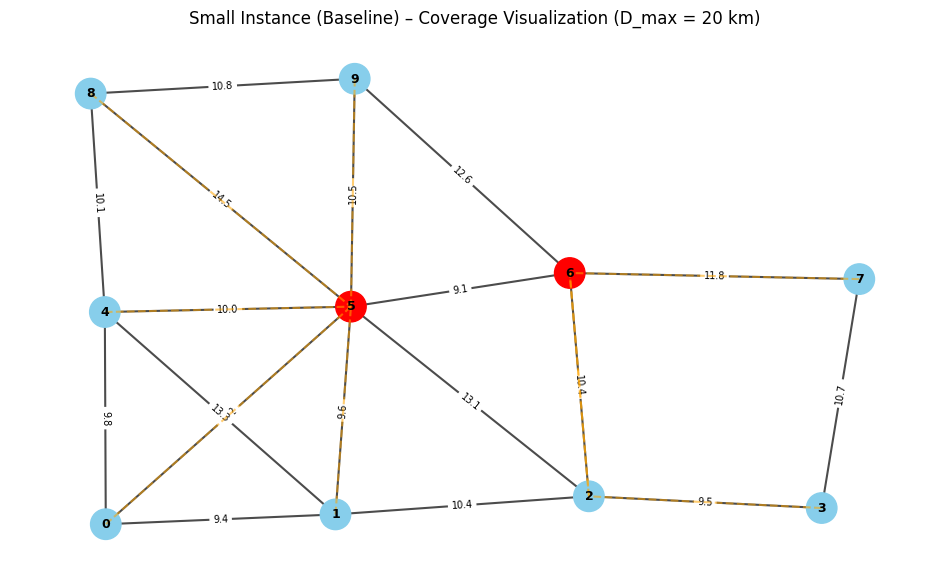

In [16]:
# ------------------------------------------------------------
# Example calls
# ------------------------------------------------------------
data_small, D_max_small = select_dataset(1, data_1, data_2, data_20)
res_small = run_instance(data_small, D_max_small, instance_name="Small Instance", model_type="Baseline")

### 1.2.2 Results - Medium Instance

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 101 rows, 198 columns and 732 nonzeros
Model fingerprint: 0xa35951de
Variable types: 158 continuous, 40 integer (40 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 4 rows and 0 columns
Presolve time: 0.00s
Presolved: 97 rows, 198 columns, 697 nonzeros
Variable types: 158 continuous, 40 integer (40 bi

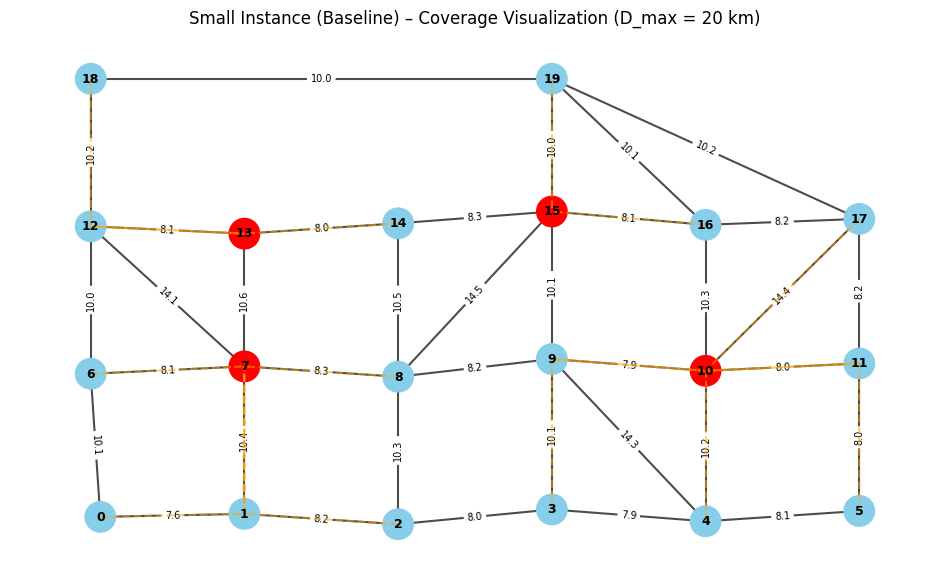

In [17]:
# ------------------------------------------------------------
# Example calls
# ------------------------------------------------------------
data_small, D_max_small = select_dataset(3, data_1, data_2 ,data_20)
res_small = run_instance(data_small, D_max_small, instance_name="Small Instance", model_type="Baseline")


### 1.2.3 Results - Large Instance

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 151 rows, 442 columns and 1678 nonzeros
Model fingerprint: 0x3a04415b
Variable types: 382 continuous, 60 integer (60 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 11 rows and 0 columns
Presolve time: 0.00s
Presolved: 140 rows, 442 columns, 1516 nonzeros
Variable types: 382 continuous, 60 integer (6

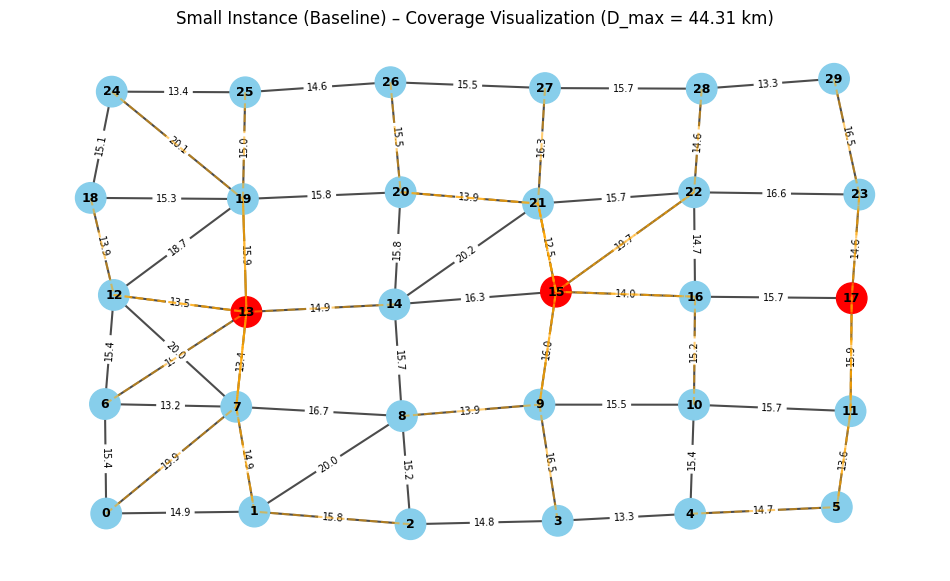

In [18]:
# ------------------------------------------------------------
# Example calls
# ------------------------------------------------------------
data_small, D_max_small = select_dataset(2, data_1, data_2, data_20)
res_small = run_instance(data_small, D_max_small, instance_name="Small Instance", model_type="Baseline")


# Section 2: Scenario A – Depot-Outage Survivability (`Scenario_A`)

## 2.1 Mathematical Formulation

Scenario A requires the fuel depot network to remain covered and connected if any single opened depot $k \in V$ goes offline. Removing $k$ from the original road network $G$ yields the surviving subgraph $G_{-k} = G(V_{-k})$ on $V_{-k} = V \setminus \{k\}$, with recomputed shortest-path distances $d_{ij}^{(-k)}$. Using these distances, we construct the post-outage reachability graph $H_{-k} = (V_{-k}, L_{-k})$ where $\{i, j\} \in L_{-k} \iff d_{ij}^{(-k)} \le D_{\max}$. Recomputing shortest paths after deleting $k$ is necessary because a feasible leg in $H$ may rely on a road path passing through $k$ and exceed $D_{\max}$ once $k$ is unavailable.

For each $k \in V$ and $i \in V_{-k}$, define:
- $N_{-k}(i) = \{j \in V_{-k} : \{i, j\} \in L_{-k}\}$: open neighborhood in $H_{-k}$,
- $N_{-k}[i] = N_{-k}(i) \cup \{i\}$: closed neighborhood in $H_{-k}$,
- $\vec{L}_{-k} = \{(i, j), (j, i) : \{i, j\} \in L_{-k}\}$: directed links in $H_{-k}$.

### Decision Variables
$$\begin{aligned}
x_i &\in \{0, 1\} && \forall i \in V && \text{(1 if a fuel depot is opened at node } i\text{)}, \\
a_{1,i},\; a_{2,i} &\in \{0, 1\} && \forall i \in V && \text{(primary and backup anchor depots)}, \\
z_{k,i} &\ge 0 && \forall k \in V,\; \forall i \in V_{-k} && \text{(connectivity flow injected at node } i \text{ under outage } k\text{)}, \\
w_{k,i} &\ge 0 && \forall k \in V,\; \forall i \in V_{-k} && \text{(post-outage flow demand at node } i \text{ under outage } k\text{)}, \\
y_{k,i,j} &\ge 0 && \forall k \in V,\; \forall (i, j) \in \vec{L}_{-k} && \text{(auxiliary flow on link } (i, j) \text{ under outage } k\text{)}.
\end{aligned}$$

### Model
$$\min \sum_{i \in V} x_i \tag{A-0}$$
subject to:
$$\sum_{i \in V} a_{1,i} = 1, \quad \sum_{i \in V} a_{2,i} = 1 \tag{A-1}$$
$$a_{1,i} + a_{2,i} \le x_i \quad \forall i \in V \tag{A-2}$$
$$\sum_{j \in N[i]} x_j \ge 2 \quad \forall i \in V \tag{A-3}$$
$$\sum_{j \in N_{-k}[i]} x_j \ge x_k \quad \forall k \in V,\; \forall i \in V_{-k} \tag{A-4}$$
$$\sum_{j \in N_{-k}(i)} y_{k,i,j} - \sum_{j \in N_{-k}(i)} y_{k,j,i} = z_{k,i} - w_{k,i} \quad \forall k \in V,\; \forall i \in V_{-k} \tag{A-5}$$
$$w_{k,i} \ge x_i + x_k - 1 \quad \forall k \in V,\; \forall i \in V_{-k} \tag{A-6}$$
$$z_{k,i} \le n \cdot (a_{1,i} + a_{2,i}) \quad \forall k \in V,\; \forall i \in V_{-k} \tag{A-7}$$
$$z_{k,i} \le n \cdot (a_{1,i} + a_{1,k}) \quad \forall k \in V,\; \forall i \in V_{-k} \tag{A-8}$$
$$\sum_{i \in N_{-k}(j)} y_{k,i,j} \le (n - 1) x_j \quad \forall k \in V,\; \forall j \in V_{-k} \tag{A-9}$$
$$x_i, a_{1,i}, a_{2,i} \in \{0, 1\} \;\; \forall i \in V, \qquad z_{k,i}, w_{k,i} \ge 0 \;\; \forall k \in V, i \in V_{-k}, \qquad y_{k,i,j} \ge 0 \;\; \forall k \in V, (i, j) \in \vec{L}_{-k} \tag{A-10}$$

### Formulation Logic
- **Intact and Post-Outage Coverage (A-3)–(A-4):** Every node has at least two depots in its closed neighborhood in $H$. When an opened depot $k$ fails ($x_k = 1$), every surviving node must still have at least one depot in its closed neighborhood in $H_{-k}$.
- **Depot-Only Outage Gating (A-5)–(A-6):** When $x_k = 1$, every surviving depot ($x_i = 1$) requires $w_{k,i} \ge 1$ unit of flow. When $x_k = 0$, $w_{k,i}$ can be set to $0$ and no flow is needed.
- **Single Active Anchor (A-7)–(A-8):** If the primary anchor survives ($a_{1,k} = 0$), (A-8) forces $z_{k,i} = 0$ for all nodes except the primary anchor. If the primary anchor fails ($a_{1,k} = 1$), $a_{1,i} = 0$ for all $i \in V_{-k}$ and (A-7) restricts flow injection exclusively to the backup anchor $a_2$.
- **Depot-Only Transit (A-9):** Flow can only enter opened depots, ensuring the surviving depots form a single connected component in $H_{-k}$.


## 2.2 Implementation

Implement the model in the cell below.

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1


Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 562 rows, 582 columns and 2856 nonzeros
Model fingerprint: 0xdf5b747b
Variable types: 552 continuous, 30 integer (30 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Presolve removed 70 rows and 0 columns
Presolve time: 0.01s
Presolved: 492 rows, 582 columns, 2392 nonzeros
Variable types: 552 continuous, 30 integer (30 binary)
Found heuristic solution: objective 6.0000000
Root relaxation presolve removed 19 rows and 0 columns
Root relaxation presolved: 473 rows, 582 columns, 2303 nonzeros


Root relaxation: objecti

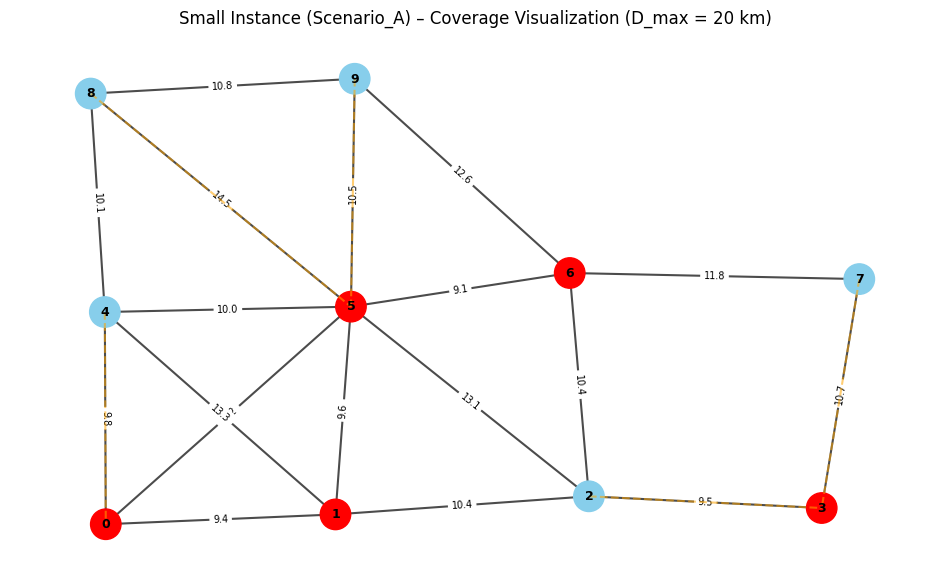

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 2322 rows, 3270 columns and 15378 nonzeros
Model fingerprint: 0x3de5d1fb
Variable types: 3210 continuous, 60 integer (60 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Presolve removed 160 rows and 0 columns
Presolve time: 0.03s
Presolved: 2162 rows, 3270 columns, 13647 nonzeros
Variable types: 3210 continuous, 60 i

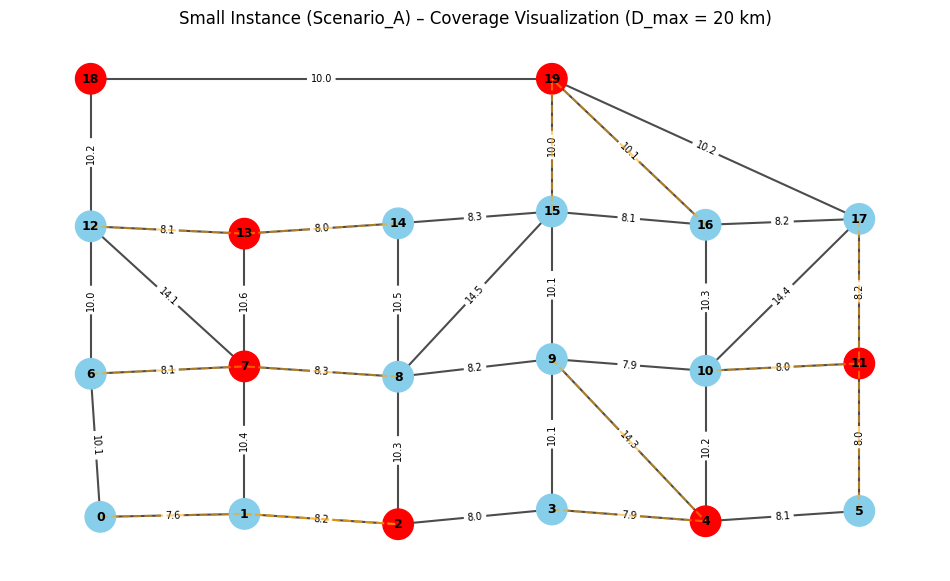

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 5282 rows, 11490 columns and 51352 nonzeros
Model fingerprint: 0xb97e4d5f
Variable types: 11400 continuous, 90 integer (90 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Presolve removed 460 rows and 0 columns
Presolve time: 0.10s
Presolved: 4822 rows, 11490 columns, 44011 nonzeros
Variable types: 11400 continuous, 

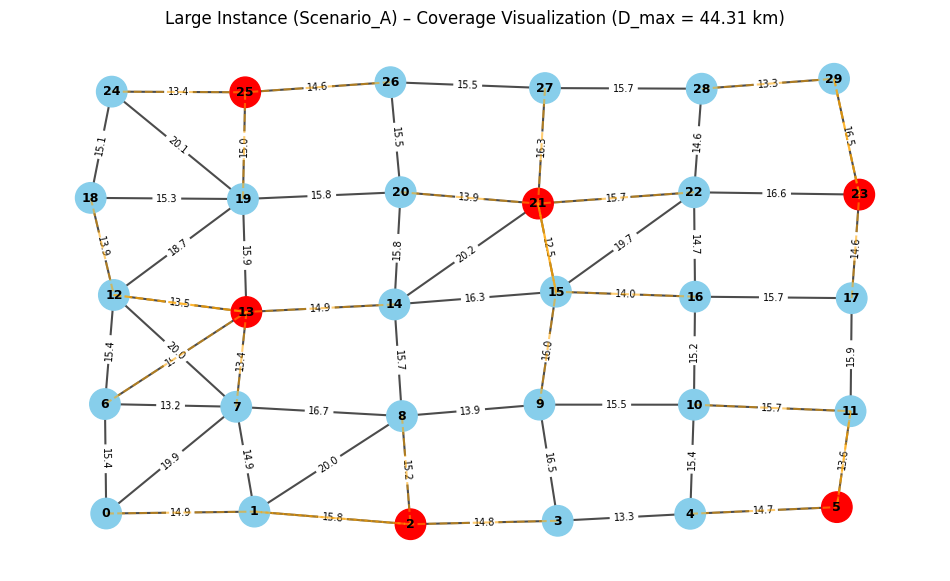

In [19]:
# ------------------------------------------------------------
# Construct post-failure closure graphs G_p^c = [G_p]^c for all p in V
# ------------------------------------------------------------
def construct_post_failure_closures(G, D_max):
    V = list(G.nodes())
    V_p = {}
    neighbors_p = {}
    A_p_c = {}

    for p in V:
        surviving = [v for v in V if v != p]
        V_p[p] = surviving

        # Induced subgraph without node p, then recompute shortest paths
        G_p = G.subgraph(surviving)
        sp_p = dict(nx.all_pairs_dijkstra_path_length(G_p, weight="weight"))

        neighbors_p[p] = {
            i: [
                j
                for j in surviving
                if j != i and sp_p[i].get(j, float("inf")) <= D_max
            ]
            for i in surviving
        }

        A_p_c[p] = [
            (i, j) for i in surviving for j in neighbors_p[p][i]
        ]

    return V_p, neighbors_p, A_p_c


# ------------------------------------------------------------
# Build the Hub-Failure Survivability model (Scenario_A: PRF-Obj to PRF-9)
# ------------------------------------------------------------
# ------------------------------------------------------------
# Build the Scenario A Depot-Outage Survivability model (A-0 to A-9)
# ------------------------------------------------------------
def build_model_A(V, neighbors, V_p, A_p_c, neighbors_p):
    n = len(V)

    model = gp.Model("Fuel_Depot_Scenario_A")

    # Solver parameters
    model.setParam("MIPGap", 0.0)
    model.setParam("Threads", 1)
    model.setParam("Seed", 1)
    model.setParam("MIPFocus", 1)
    model.setParam("Presolve", 2)
    model.setParam("Heuristics", 0.1)

    ############################################################################
    # 1. Decision Variables
    ############################################################################
    # x[i] = 1 if a fuel depot is opened at node i
    x = model.addVars(V, vtype=GRB.BINARY, name="x")

    # a1[i], a2[i] = 1 if node i is chosen as primary / backup anchor depot
    a1 = model.addVars(V, vtype=GRB.BINARY, name="a1")
    a2 = model.addVars(V, vtype=GRB.BINARY, name="a2")

    # z[k, i] >= 0 flow injected at node i under outage k
    # w[k, i] >= 0 flow demand at node i under outage k
    node_keys = [(k, i) for k in V for i in V_p[k]]
    z = model.addVars(node_keys, lb=0.0, vtype=GRB.CONTINUOUS, name="z")
    w = model.addVars(node_keys, lb=0.0, vtype=GRB.CONTINUOUS, name="w")

    # y[k, i, j] >= 0 auxiliary flow on directed link (i, j) under outage k
    y_keys = [(k, i, j) for k in V for (i, j) in A_p_c[k]]
    y = model.addVars(y_keys, lb=0.0, vtype=GRB.CONTINUOUS, name="y")

    ############################################################################
    # 2. Objective (A-0): Minimize total number of opened fuel depots
    ############################################################################
    model.setObjective(gp.quicksum(x[i] for i in V), GRB.MINIMIZE)

    ############################################################################
    # 3. Constraints
    ############################################################################
    # (A-1) Exactly one primary anchor and one backup anchor
    model.addConstr(gp.quicksum(a1[i] for i in V) == 1, name="Primary_Anchor_Count")
    model.addConstr(gp.quicksum(a2[i] for i in V) == 1, name="Backup_Anchor_Count")

    # (A-2) Anchors must be distinct and opened as fuel depots
    model.addConstrs((a1[i] + a2[i] <= x[i] for i in V), name="Distinct_Open_Anchors")

    # (A-3) Intact closed-neighborhood double coverage
    model.addConstrs(
        (x[i] + gp.quicksum(x[j] for j in neighbors[i]) >= 2 for i in V),
        name="Intact_Double_Coverage",
    )

    # (A-4) Post-outage closed-neighborhood coverage when opened depot k fails
    model.addConstrs(
        (
            x[i] + gp.quicksum(x[j] for j in neighbors_p[k][i]) >= x[k]
            for k in V
            for i in V_p[k]
        ),
        name="Post_Depot_Outage_Coverage",
    )

    # (A-5) Post-outage flow-balance equalities
    model.addConstrs(
        (
            gp.quicksum(y[k, i, j] for j in neighbors_p[k][i])
            - gp.quicksum(y[k, j, i] for j in neighbors_p[k][i])
            == z[k, i] - w[k, i]
            for k in V
            for i in V_p[k]
        ),
        name="Post_Outage_Flow_Balance",
    )

    # (A-6) Depot-only outage demand gating (active when both x[k] = 1 and x[i] = 1)
    model.addConstrs(
        (
            w[k, i] >= x[i] + x[k] - 1
            for k in V
            for i in V_p[k]
        ),
        name="Post_Outage_Demand_Gate",
    )

    # (A-7) Only primary or backup anchor can inject flow
    model.addConstrs(
        (
            z[k, i] <= n * (a1[i] + a2[i])
            for k in V
            for i in V_p[k]
        ),
        name="Anchor_Injection_Limit",
    )

    # (A-8) Backup anchor can inject flow only when primary anchor k fails
    model.addConstrs(
        (
            z[k, i] <= n * (a1[i] + a1[k])
            for k in V
            for i in V_p[k]
        ),
        name="Single_Active_Anchor",
    )

    # (A-9) Flow can only enter opened fuel depots
    model.addConstrs(
        (
            gp.quicksum(y[k, i, j] for i in neighbors_p[k][j]) <= (n - 1) * x[j]
            for k in V
            for j in V_p[k]
        ),
        name="Post_Outage_Flow_Into_Open_Only",
    )

    return model, x, a1, a2, y


# ------------------------------------------------------------
# Example calls
# ------------------------------------------------------------
res_small_rlprf = run_instance(data_1, 20, instance_name="Small Instance", model_type="Scenario_A")
res_medium_rlprf = run_instance(data_20, 20, instance_name="Small Instance", model_type="Scenario_A")
res_large_rlprf = run_instance(data_2, 44.31, instance_name="Large Instance", model_type="Scenario_A")

# Section 3: Scenario B – Any-Node Outage Survivability (`Scenario_B`)

## 3.1 Mathematical Formulation

Scenario B extends Scenario A by requiring coverage and backbone connectivity after the disruption of **any** node $k \in V$, whether $k$ hosts a fuel depot or not. Removing a non-depot road junction can still break shortest paths and disconnect surviving depots in $H_{-k}$.

Two simplifications occur relative to Scenario A because post-outage survivability is now enforced unconditionally for every $k \in V$:
- **Post-outage coverage (N-4):** Every surviving node must have at least one opened depot in its closed neighborhood $N_{-k}[i]$, regardless of whether $x_k = 1$ or $x_k = 0$.
- **Unconditional flow demand (N-5):** The gating variable $w_{k,i}$ is no longer needed; every surviving depot $i \in V_{-k}$ directly consumes $x_i$ units of flow in every outage scenario $k \in V$.

### Model
$$\min \sum_{i \in V} x_i \tag{N-0}$$
subject to:
$$\sum_{i \in V} a_{1,i} = 1, \quad \sum_{i \in V} a_{2,i} = 1 \tag{N-1}$$
$$a_{1,i} + a_{2,i} \le x_i \quad \forall i \in V \tag{N-2}$$
$$\sum_{j \in N[i]} x_j \ge 2 \quad \forall i \in V \tag{N-3}$$
$$\sum_{j \in N_{-k}[i]} x_j \ge 1 \quad \forall k \in V,\; \forall i \in V_{-k} \tag{N-4}$$
$$\sum_{j \in N_{-k}(i)} y_{k,i,j} - \sum_{j \in N_{-k}(i)} y_{k,j,i} = z_{k,i} - x_i \quad \forall k \in V,\; \forall i \in V_{-k} \tag{N-5}$$
$$z_{k,i} \le n \cdot (a_{1,i} + a_{2,i}) \quad \forall k \in V,\; \forall i \in V_{-k} \tag{N-6}$$
$$z_{k,i} \le n \cdot (a_{1,i} + a_{1,k}) \quad \forall k \in V,\; \forall i \in V_{-k} \tag{N-7}$$
$$\sum_{i \in N_{-k}(j)} y_{k,i,j} \le (n - 1) x_j \quad \forall k \in V,\; \forall j \in V_{-k} \tag{N-8}$$
$$x_i, a_{1,i}, a_{2,i} \in \{0, 1\} \;\; \forall i \in V, \qquad z_{k,i} \ge 0 \;\; \forall k \in V, i \in V_{-k}, \qquad y_{k,i,j} \ge 0 \;\; \forall k \in V, (i, j) \in \vec{L}_{-k} \tag{N-9}$$

Summing (N-5) over $i \in V_{-k}$ forces $\sum_{i \in V_{-k}} z_{k,i} = \sum_{i \in V_{-k}} x_i$ for every $k \in V$. Constraints (N-6)–(N-7) ensure that only the surviving active anchor injects this flow, and (N-8) restricts transit to opened depots, guaranteeing that the surviving depots remain connected in $H_{-k}$ after any single node outage.

## 3.2 Implementation

Implement the  model in the cell below.

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1


Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 472 rows, 492 columns and 2496 nonzeros
Model fingerprint: 0x4ef34217
Variable types: 462 continuous, 30 integer (30 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Presolve removed 90 rows and 0 columns
Presolve time: 0.00s
Presolved: 382 rows, 492 columns, 2029 nonzeros
Variable types: 462 continuous, 30 integer (30 binary)
Found heuristic solution: objective 10.0000000
Found heuristic solution: objective 9.0000000
Found heuristic solution: objective 8.0000000
Root relaxation presolve removed 1 rows and 0 column

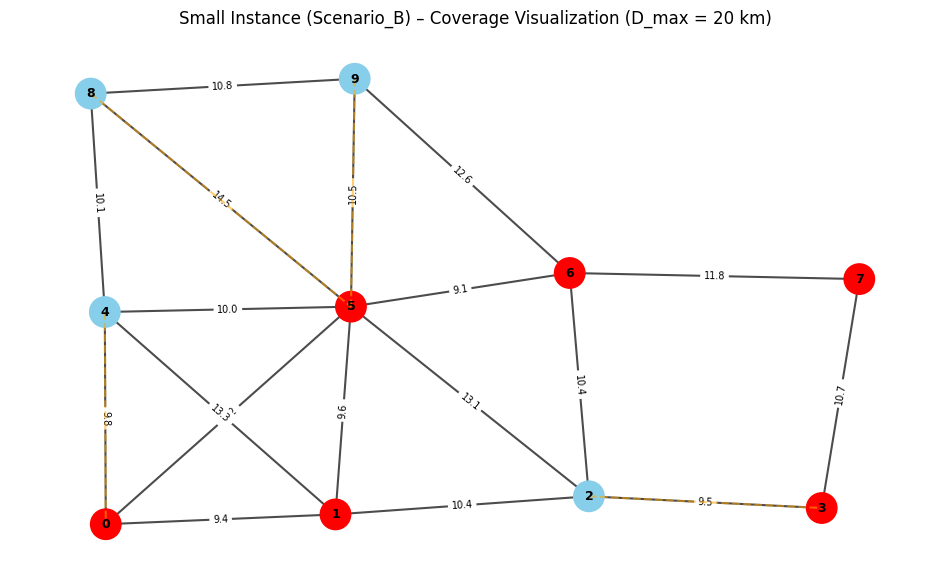

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 1942 rows, 2890 columns and 13858 nonzeros
Model fingerprint: 0xec5fb7f9
Variable types: 2830 continuous, 60 integer (60 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Presolve removed 362 rows and 0 columns
Presolve time: 0.02s
Presolved: 1580 rows, 2890 columns, 11117 nonzeros
Variable types: 2830 continuous, 60 i

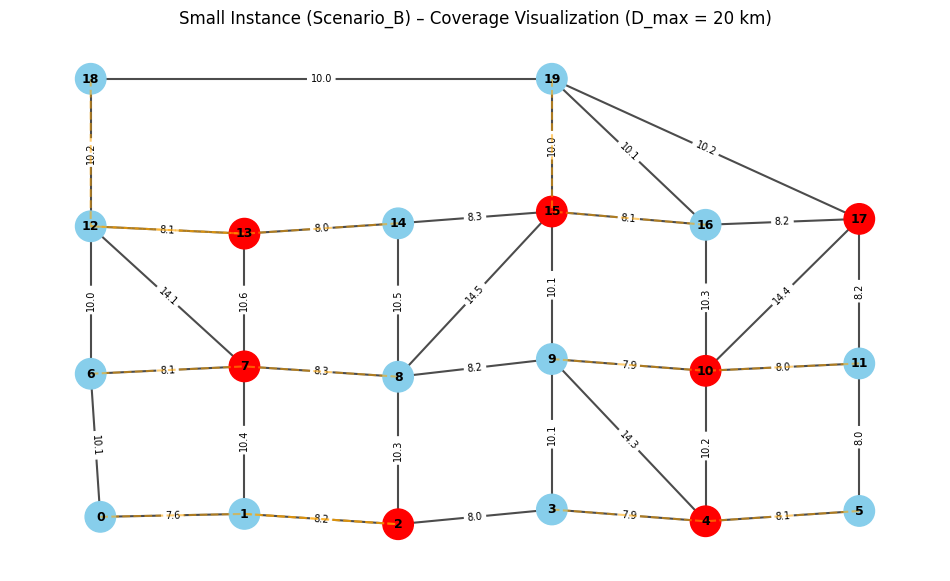

Set parameter MIPGap to value 0
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Presolve to value 2
Set parameter Heuristics to value 0.1
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
MIPGap  0
Heuristics  0.1
MIPFocus  1
Presolve  2
Seed  1
Threads  1

Optimize a model with 4412 rows, 10620 columns and 47872 nonzeros
Model fingerprint: 0x8fd96510
Variable types: 10530 continuous, 90 integer (90 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Presolve removed 829 rows and 0 columns
Presolve time: 0.09s
Presolved: 3583 rows, 10620 columns, 37704 nonzeros
Variable types: 10530 continuous, 

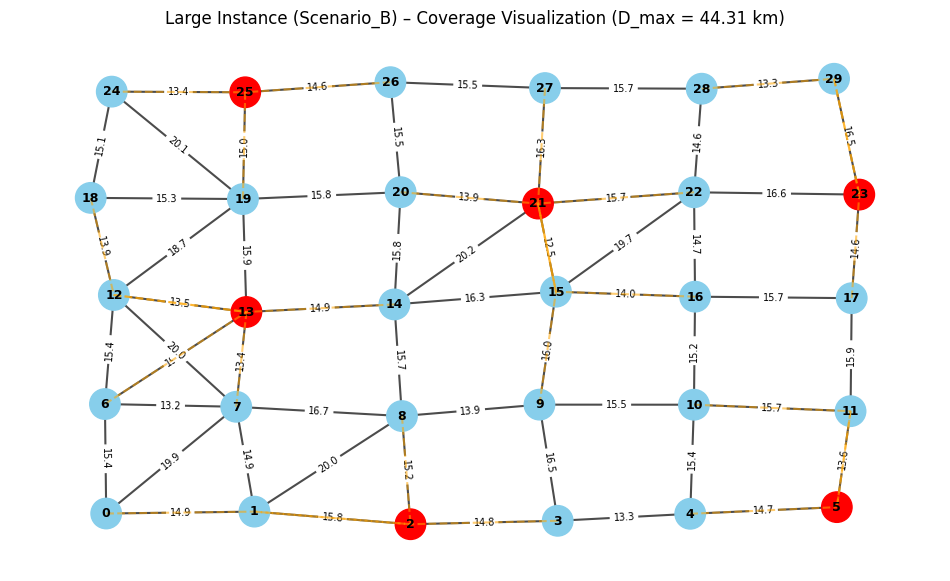

In [20]:
# ------------------------------------------------------------
# Build the Scenario B Any-Node Outage Survivability model (N-0 to N-9)
# ------------------------------------------------------------
def build_model_B(V, neighbors, V_p, A_p_c, neighbors_p):
    n = len(V)

    model = gp.Model("Fuel_Depot_Scenario_B")

    # Solver parameters
    model.setParam("MIPGap", 0.0)
    model.setParam("Threads", 1)
    model.setParam("Seed", 1)
    model.setParam("MIPFocus", 1)
    model.setParam("Presolve", 2)
    model.setParam("Heuristics", 0.1)

    ############################################################################
    # 1. Decision Variables
    ############################################################################
    # x[i] = 1 if a fuel depot is opened at node i
    x = model.addVars(V, vtype=GRB.BINARY, name="x")

    # a1[i], a2[i] = 1 if node i is chosen as primary / backup anchor depot
    a1 = model.addVars(V, vtype=GRB.BINARY, name="a1")
    a2 = model.addVars(V, vtype=GRB.BINARY, name="a2")

    # z[k, i] >= 0 flow injected at node i under outage k
    node_keys = [(k, i) for k in V for i in V_p[k]]
    z = model.addVars(node_keys, lb=0.0, vtype=GRB.CONTINUOUS, name="z")

    # y[k, i, j] >= 0 auxiliary flow on directed link (i, j) under outage k
    y_keys = [(k, i, j) for k in V for (i, j) in A_p_c[k]]
    y = model.addVars(y_keys, lb=0.0, vtype=GRB.CONTINUOUS, name="y")

    ############################################################################
    # 2. Objective (N-0): Minimize total number of opened fuel depots
    ############################################################################
    model.setObjective(gp.quicksum(x[i] for i in V), GRB.MINIMIZE)

    ############################################################################
    # 3. Constraints
    ############################################################################
    # (N-1) Exactly one primary anchor and one backup anchor
    model.addConstr(gp.quicksum(a1[i] for i in V) == 1, name="Primary_Anchor_Count")
    model.addConstr(gp.quicksum(a2[i] for i in V) == 1, name="Backup_Anchor_Count")

    # (N-2) Anchors must be distinct and opened as fuel depots
    model.addConstrs((a1[i] + a2[i] <= x[i] for i in V), name="Distinct_Open_Anchors")

    # (N-3) Intact closed-neighborhood double coverage
    model.addConstrs(
        (x[i] + gp.quicksum(x[j] for j in neighbors[i]) >= 2 for i in V),
        name="Intact_Double_Coverage",
    )

    # (N-4) Post-outage closed-neighborhood coverage for any node failure k
    model.addConstrs(
        (
            x[i] + gp.quicksum(x[j] for j in neighbors_p[k][i]) >= 1
            for k in V
            for i in V_p[k]
        ),
        name="Post_Any_Node_Outage_Coverage",
    )

    # (N-5) Post-outage flow-balance equalities for all k in V
    model.addConstrs(
        (
            gp.quicksum(y[k, i, j] for j in neighbors_p[k][i])
            - gp.quicksum(y[k, j, i] for j in neighbors_p[k][i])
            == z[k, i] - x[i]
            for k in V
            for i in V_p[k]
        ),
        name="Post_Outage_Flow_Balance_All",
    )

    # (N-6) Only primary or backup anchor can inject flow
    model.addConstrs(
        (
            z[k, i] <= n * (a1[i] + a2[i])
            for k in V
            for i in V_p[k]
        ),
        name="Anchor_Injection_Limit_All",
    )

    # (N-7) Backup anchor can inject flow only when primary anchor k fails
    model.addConstrs(
        (
            z[k, i] <= n * (a1[i] + a1[k])
            for k in V
            for i in V_p[k]
        ),
        name="Single_Active_Anchor_All",
    )

    # (N-8) Flow can only enter opened fuel depots
    model.addConstrs(
        (
            gp.quicksum(y[k, i, j] for i in neighbors_p[k][j]) <= (n - 1) * x[j]
            for k in V
            for j in V_p[k]
        ),
        name="Post_Outage_Flow_Into_Open_Only_All",
    )

    return model, x, a1, a2, y

# ------------------------------------------------------------
# Example calls for Case B (Scenario_B)
# ------------------------------------------------------------
res_small_rlpnf = run_instance(data_1, 20, instance_name="Small Instance", model_type="Scenario_B")
res_medium_rlprf = run_instance(data_20, 20, instance_name="Small Instance", model_type="Scenario_B")
res_large_rlpnf = run_instance(data_2, 44.31, instance_name="Large Instance", model_type="Scenario_B")

# 4. Summary Table

In [ ]:
# ============================
# Input data
# ============================

# Total number of nodes in each dataset
N_small = 10
N_large = 30

# Results you already know
results_small = {
    "RLP (Baseline)": 2,
    "RLPRF (Station Failure)": 5,
    "RLPNF (Node Failure)": 6  
}

results_large = {
    "RLP (Baseline)": 3,
    "RLPRF (Station Failure)": 6,
    "RLPNF (Node Failure)": 6  
}

# ============================
# Function to build summary table
# ============================

def build_summary_table(result_dict, total_nodes):
    baseline = list(result_dict.values())[0]

    rows = []
    for model, stations in result_dict.items():

        if stations is None:
            percent_nodes = None
            increase = None
        else:
            percent_nodes = 100 * stations / total_nodes
            increase = None if model == "RLP (Baseline)" else 100 * (stations - baseline) / baseline

        rows.append({
            "Model": model,
            "Charging Sites": stations,
            "% of Nodes": None if percent_nodes is None else f"{percent_nodes:.1f}%",
            "Increase from Baseline": None if increase is None else f"{increase:.1f}%"
        })

    return pd.DataFrame(rows)

# ============================
# Create both summary tables
# ============================

summary_small = build_summary_table(results_small, N_small)
print("\n\033[1m Summary Table: Small Dataset ")
display(summary_small)

summary_large = build_summary_table(results_large, N_large)
print("\n\033[1m Summary Table: Large Dataset ")
display(summary_large)




 Summary Table: Small Dataset 


,Model,Charging Sites,% of Nodes,Increase from Baseline
0,RLP (Baseline),2,20.0%,None
1,RLPRF (Station Failure),5,50.0%,150.0%
2,RLPNF (Node Failure),6,60.0%,200.0%



 Summary Table: Large Dataset 


,Model,Charging Sites,% of Nodes,Increase from Baseline
0,RLP (Baseline),3,10.0%,None
1,RLPRF (Station Failure),6,20.0%,100.0%
2,RLPNF (Node Failure),6,20.0%,100.0%
